# 01. Formal Exploratory Data Analysis

Structured deep-dive into the dataset. Builds on the preliminary EDA with richer diagnostics.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
%matplotlib inline
print("Libraries loaded correctly")

Libraries loaded correctly


In [3]:
raw_dir = Path.cwd().parent.parent / "data" / "raw"
raw_dir.mkdir(parents=True, exist_ok=True)

csv_files = list(raw_dir.glob("*.csv"))
if not csv_files:
    raise FileNotFoundError(f"Place a CSV in {raw_dir}")

file_path = csv_files[0]
df = pd.read_csv(file_path, encoding="utf-8", low_memory=False)
print(f"Loaded: {file_path.name}")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]:,} columns")
print("Working with Devices CSV")

Loaded: devices-1681209661.csv
Shape: 118,249 rows x 15 columns
Working with Devices CSV


## 1. Schema Audit

Complete column-by-column diagnostic: type, nulls, cardinality, memory.

In [4]:
schema = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "non_null": df.notna().sum(),
    "null_pct": (df.isna().mean() * 100).round(2),
    "cardinality": df.nunique(dropna=False),
    "memory_kb": (df.memory_usage(deep=True) / 1024).round(1)
})
display(schema)
print(f"Total memory: {schema['memory_kb'].sum():,.1f} KB")

,dtype,non_null,null_pct,cardinality,memory_kb
Index,NaN,NaN,NaN,NaN,0.1
classification,str,35601.0,69.89,17.0,5255.5
code,str,36218.0,69.37,3024.0,4539.2
country,str,118248.0,0.00,47.0,6004.8
created_at,str,118249.0,0.00,8627.0,8314.4
description,str,89606.0,24.22,60799.0,17674.5
distributed_to,str,33626.0,71.56,12028.0,10307.5
id,int64,118249.0,0.00,118249.0,923.8
implanted,str,34898.0,70.49,3.0,4351.7
manufacturer_id,int64,118249.0,0.00,31716.0,923.8


Total memory: 130,968.3 KB


In [5]:
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = df.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical: {len(num_cols)}  |  Categorical: {len(cat_cols)}")

Numerical: 2  |  Categorical: 13


In [6]:
 df.select_dtypes(include=[np.number]).columns.tolist()

['id', 'manufacturer_id']

In [7]:
print((df['id']==df['manufacturer_id']).sum()/df.shape[0])

5.919711794602914e-05


Looks like manufacturer_id will be a foreing key to another csv in the study case, I will be checking that in the EDA of the other CSVs.

## 2. Missing Values - Full Diagnosis

In [8]:
missing_cols = schema[schema["null_pct"] > 0][["null_pct"]].sort_values("null_pct", ascending=False)
if not missing_cols.empty:
    display(missing_cols)
else:
    print("No missing values.")

,null_pct
quantity_in_commerce,73.00
risk_class,72.14
distributed_to,71.56
implanted,70.49
classification,69.89
code,69.37
number,46.05
description,24.22
name,0.03


Rows with >=X nulls:
  >=  1: 87,693 ( 74.2%)
  >=  2: 85,323 ( 72.2%)
  >=  5: 84,633 ( 71.6%)
  >= 10:      1 (  0.0%)
  >= 20:      0 (  0.0%)
  >= 50:      0 (  0.0%)


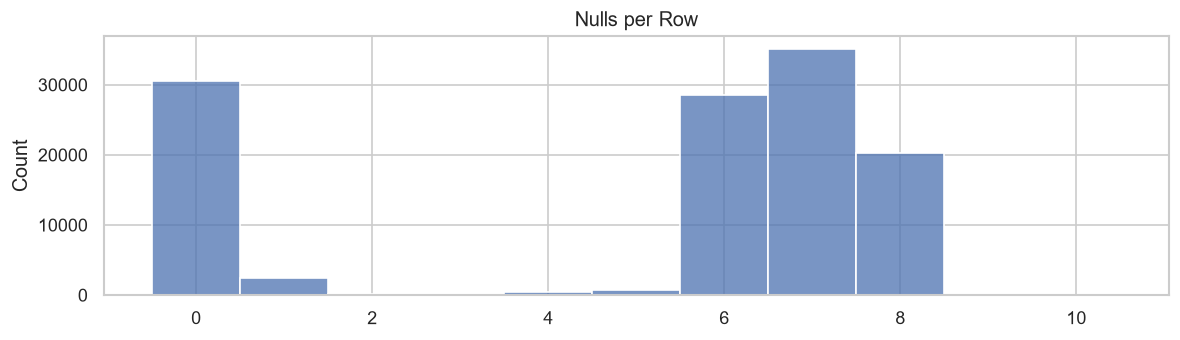

In [9]:
nulls_per_row = df.isna().sum(axis=1)
print("Rows with >=X nulls:")
for t in [1, 2, 5, 10, 20, 50]:
    n = (nulls_per_row >= t).sum()
    print(f"  >={t:>3}: {n:>6,} ({n/len(df)*100:>5.1f}%)")

if nulls_per_row.max() > 0:
    plt.figure(figsize=(10, 3))
    sns.histplot(nulls_per_row, bins=min(50, nulls_per_row.max()+1), discrete=True)
    plt.title("Nulls per Row")
    plt.tight_layout()
    plt.show()

In [10]:
null_pct = df.isna().mean() * 100 #Esto calcula porciento, remember True=1
null_pct.sort_values(ascending=False)

quantity_in_commerce    72.998503
risk_class              72.136762
distributed_to          71.563396
implanted               70.487700
classification          69.893191
code                    69.371411
number                  46.046055
description             24.222615
name                     0.026216
country                  0.000846
id                       0.000000
slug                     0.000000
manufacturer_id          0.000000
created_at               0.000000
updated_at               0.000000
dtype: float64

Puedo hacer un drop de las columnas que tienen un % mayor a 40%. No sirve la cantidad de nulls para el análisis.  
| Columna | Porciento de nulls (%) |
| :--- | :--- |
| quantity_in_commerce |    72.99850 |  
| risk_class |             72.136762 |  
| distributed_to |         71.563396 |  
| implanted |              70.487700 |  
| classification |         69.893191 |  
| code |                   69.371411 |  
| number |                 46.046055 |  

In [11]:
df.shape[0]*0.33

39022.17

In [12]:
df.head(2)

,id,classification,code,description,distributed_to,implanted,name,number,quantity_in_commerce,risk_class,slug,country,manufacturer_id,created_at,updated_at
0,1,NaN,NaN,IVD Other,NaN,NaN,Cell-Dyn Emerald Cleanser,NaN,NaN,NaN,tur-cell-dyn-emerald-cleanser,TUR,1,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC
1,2,NaN,NaN,Class IIB,NaN,NaN,"TECNIS Monofocal 1-piece, TECNIS 1-Piece IOL w...",NaN,NaN,NaN,tur-tecnis-monofocal-1-piece-tecnis-1-piece-io...,TUR,2,2022-08-04 08:28:00 UTC,2022-08-04 08:28:00 UTC


In [13]:
print((df['created_at']==df['updated_at']).sum()/df.shape[0])

0.9930739372003146


El valor anterior me dice que la columna "created_at" y "updated_at" son iguales el 99.31% de los casos. Para este análisis haré el drop de la columna "updated_at".

## 3. Numerical Analysis

In [14]:
df['manufacturer_id'].unique()

array([    1,     2,     3, ..., 31825, 31826, 31827], shape=(31716,))

In [15]:
df['manufacturer_id'].duplicated().sum()

np.int64(86533)

In [16]:
type(num_cols)

list

In [17]:
num_cols[1]

'manufacturer_id'

In [18]:
if num_cols:
    stats = df[num_cols[1]].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
    
    stats["skew"] = df[num_cols[1]].skew().round(3)
    stats["kurtosis"] = df[num_cols[1]].kurtosis().round(3)
    display(stats)

count       118249.000000
mean         15022.948321
std           9117.177777
min              1.000000
1%             614.480000
5%            2110.000000
25%           6097.000000
50%          14880.000000
75%          24087.000000
95%          30245.600000
99%          31095.520000
max          31827.000000
skew             0.138000
kurtosis        -1.319000
Name: manufacturer_id, dtype: float64

Esta columna numérica me servirá para hacer análisis junto con el resto de datos.

## 4. Categorical Analysis

In [19]:
if cat_cols:
    cat_summary = pd.DataFrame({
        "unique": df[cat_cols].nunique().sort_values(ascending=False),
        "top_val": [df[c].value_counts(dropna=False).index[0] if df[c].nunique() > 0 else None for c in cat_cols],
        "top_pct": [round(df[c].value_counts(dropna=False).iloc[0] / len(df) * 100, 1) for c in cat_cols]
    })
    display(cat_summary)

,unique,top_val,top_pct
slug,118249,NaN,69.9
name,93077,NaN,69.4
description,60798,NaN,24.2
number,59652,NaN,71.6
quantity_in_commerce,15212,NaN,70.5
distributed_to,12027,Device Recall Customed,0.3
updated_at,8629,NaN,46.0
created_at,8627,NaN,73.0
code,3023,NaN,72.1
country,46,tur-cell-dyn-emerald-cleanser,0.0


In [20]:
len(df['implanted'].unique())

3

Las columnas tienen un valor adicional al que dice la columna unique anterior, esto por el conteo literal que hace la celda anterior.

In [21]:
df['risk_class'].unique()

<StringArray>
[nan, 'II', '2', '1', '3', 'Not Classified', 'Unclassified', 'HDE']
Length: 8, dtype: str

In [22]:
df['risk_class'].isna().sum()

np.int64(85301)

In [23]:
df.shape

(118249, 15)

In [24]:
test = df.copy()

In [25]:
test = test.dropna()

In [26]:
test.head()

,id,classification,code,description,distributed_to,implanted,name,number,quantity_in_commerce,risk_class,slug,country,manufacturer_id,created_at,updated_at
12529,12530,General Hospital and Personal Use Devices,LBI,"Replacement LED PCB Kit, part number 001840, o...",worldwide,NO,Device Recall Natus neoBLUE 2 Phototherapy sy...,All distributed Natus neoBLUE 2 systems with L...,1907 total (1413 in US and 494 international),2,usa-general-hospital-and-personal-use-devices-...,USA,4827,2022-08-04 08:32:48 UTC,2022-08-04 08:32:48 UTC
12530,12531,General Hospital and Personal Use Devices,FPA,ACCU-CHEK Tender II 13/80 10 + 10 pieces || Pr...,US Nationwide Distribution,NO,Device Recall ACCUCHEK Tender II Infusion Set,Catalog: 04541472001 and lots: 5053291 and 507...,"Total of 13,041 boxes",2,usa-general-hospital-and-personal-use-devices-...,USA,4828,2022-08-04 08:32:48 UTC,2022-08-04 08:32:48 UTC
12531,12532,General Hospital and Personal Use Devices,FPA,ACCU-CHEK Tender II 13/110 10 + 10 pieces || P...,US Nationwide Distribution,NO,Device Recall ACCUCHEK Tender II Infusion Set,Catalog: 04541456001 and lot: 5052067,"Total of 13,041 boxes",2,usa-general-hospital-and-personal-use-devices-...,USA,4828,2022-08-04 08:32:48 UTC,2022-08-04 08:32:48 UTC
12532,12533,General Hospital and Personal Use Devices,FPA,ACCU-CHEK Tender II 17/60 10 + 10 pieces || Pr...,US Nationwide Distribution,NO,Device Recall ACCUCHEK Tender II Infusion Set,"Catalog: 04541502001 and lots: 5044353, 504667...","Total of 13,041 boxes",2,usa-general-hospital-and-personal-use-devices-...,USA,4828,2022-08-04 08:32:48 UTC,2022-08-04 08:32:48 UTC
12533,12534,General Hospital and Personal Use Devices,FPA,ACCU-CHEK Tender II 17/80 10 + 10 pieces || Pr...,US Nationwide Distribution,NO,Device Recall ACCUCHEK Tender II Infusion Set,"Catalog: 04541529001 and lots: 5044354, 505130...","Total of 13,041 boxes",2,usa-general-hospital-and-personal-use-devices-...,USA,4828,2022-08-04 08:32:48 UTC,2022-08-04 08:32:48 UTC


In [27]:
test['slug'].unique()[:5]

<StringArray>
[     'usa-general-hospital-and-personal-use-devices-device-recall-natus-neoblue-2-phototherapy-system',
          'usa-general-hospital-and-personal-use-devices-device-recall-accuchek-tender-ii-infusion-set',
 'usa-general-hospital-and-personal-use-devices-device-recall-accuchek-tender-ii-infusion-set-c5d309c9',
 'usa-general-hospital-and-personal-use-devices-device-recall-accuchek-tender-ii-infusion-set-81a910d7',
 'usa-general-hospital-and-personal-use-devices-device-recall-accuchek-tender-ii-infusion-set-830a10dc']
Length: 5, dtype: str

I´m gonna keep the slug for foward analysis. This column may have relation with another CSV, otherwise it will be droped.

In [28]:
test.groupby('implanted')['implanted'].count()

implanted
NO     23984
YES     6572
Name: implanted, dtype: int64

In [29]:
test.shape

(30556, 15)

I can make a drop of the rows, no de las columnas.

In [30]:
df=test.copy()

## 5. Correlation Analysis

I need to analyze the dependency relations.

In [31]:
cross_tab = pd.crosstab(df['risk_class'], df['implanted'])
print(cross_tab)

implanted          NO   YES
risk_class                 
1                5331     0
2               17831  5127
3                 591  1392
HDE                 4    11
Not Classified     31     2
Unclassified      196    40


In [32]:
desclasificados = df.loc[(test['risk_class'] == 'Not Classified') | (test['risk_class'] == 'Unclassified')]


In [33]:
desclasificados.shape

(269, 15)

In [34]:
desclasificados['risk_class']= desclasificados.loc[desclasificados['risk_class'] == 'Not Classified'] = 'Unclassified'

In [35]:
desclasificados['risk_class'].unique()

<StringArray>
['Unclassified']
Length: 1, dtype: str

In [36]:
desclasificados['risk_class'].count()

np.int64(269)

In [37]:
desclasificados.loc[(desclasificados['risk_class'] == 'Not Classified')]

,id,classification,code,description,distributed_to,implanted,name,number,quantity_in_commerce,risk_class,slug,country,manufacturer_id,created_at,updated_at


In [38]:
test.loc[test['risk_class'] == 'Not Classified', 'risk_class'] = 'Unclassified'

In [39]:
test.columns

Index(['id', 'classification', 'code', 'description', 'distributed_to',
       'implanted', 'name', 'number', 'quantity_in_commerce', 'risk_class',
       'slug', 'country', 'manufacturer_id', 'created_at', 'updated_at'],
      dtype='str')

In [40]:
cross_tab = pd.crosstab(test['risk_class'], test['implanted'])
print(cross_tab)

implanted        NO   YES
risk_class               
1              5331     0
2             17831  5127
3               591  1392
HDE               4    11
Unclassified    227    42


In [41]:
df['code'].unique()

<StringArray>
['LBI', 'FPA', 'MEC', 'JQP', 'IZI', 'LYJ', 'GCJ', 'FMI', 'OUG', 'JAK',
 ...
 'JTW', 'MUD', 'REG', 'LBJ', 'EZQ', 'OJZ', 'LWE', 'HGC', 'KTW', 'IDP']
Length: 2042, dtype: str

In [42]:
cross_tab = pd.crosstab(df['risk_class'], df['implanted'])
print(cross_tab)

implanted          NO   YES
risk_class                 
1                5331     0
2               17831  5127
3                 591  1392
HDE                 4    11
Not Classified     31     2
Unclassified      196    40


In [43]:
df['number'].head(3)

12529    All distributed Natus neoBLUE 2 systems with L...
12530    Catalog: 04541472001 and lots: 5053291 and 507...
12531                Catalog: 04541456001 and lot: 5052067
Name: number, dtype: str

I won´t use the information in the 'number' column.

## 6. Outlier Analysis

Como el dataframe tiene dos columnas numéricas solamente que son id y una posible clave foránea entonces el análsis de outliers se enfocará en detectar patrones de escrituras y errores en las otras columnas.

In [44]:
print(df['classification'].dtype)

str


In [45]:
(~df['classification'].str.isdigit()).sum()

np.int64(30556)

In [46]:
(df['classification'].str.isalpha())

12529     False
12530     False
12531     False
12532     False
12533     False
          ...  
104291    False
104292    False
104293    False
104294    False
104295    False
Name: classification, Length: 30556, dtype: bool

In [47]:
s1 = pd.Series(["one", "one1", "1", "", "Arizo y yo"])
s1.str.isalpha()

0     True
1    False
2    False
3    False
4    False
dtype: bool

In [48]:
def isAlphaOnly(text):
    return text.replace(' ','').replace('-','').replace(',','').isalpha()

In [49]:
result = pd.DataFrame()

for c in cat_cols:
    is_alpha_and_not_empty = df[c].apply(isAlphaOnly) & ~df[c].astype(str).str.isdigit() & (df[c] != '')
    result[c] = is_alpha_and_not_empty.values

print(result.sum())

classification          30556
code                    30556
description               514
distributed_to           5536
implanted               30556
name                    18647
number                   1163
quantity_in_commerce      122
risk_class                284
slug                    13304
country                 30556
created_at                  0
updated_at                  0
dtype: int64


In [50]:
df[cat_cols].sample(n=3, random_state=2) 

,classification,code,description,distributed_to,implanted,name,number,quantity_in_commerce,risk_class,slug,country,created_at,updated_at
21685,Cardiovascular Devices,MKJ,Powerheart AED G3 Automated External Defibrill...,"Throughout the United States, Canada and Europe.",NO,Device Recall Powerheart AED G3,Model no. 9300P serial numbers: 900290 thru 9...,193,3,usa-cardiovascular-devices-device-recall-power...,USA,2022-08-04 08:39:00 UTC,2022-08-04 08:39:00 UTC
99022,Hematology and Pathology Devices,GKZ,Coulter MAXM Hematology Analyzer and MAXM Hema...,"Worldwide Distribution -- US, Algeria, Andorra...",NO,Device Recall Coulter MAXM Hematology Analyze...,All serial numbers.,4288 units total,2,usa-hematology-and-pathology-devices-device-re...,USA,2022-08-04 10:15:41 UTC,2022-08-04 10:15:41 UTC
100656,Cardiovascular Devices,DQY,Multi-Lumen Central Venous Catheterization || Kit,"US Distribution including the states of MD, NC...",NO,Arrow MultiLumen Central Venous Catheterization,Catolog No - AK-12703 lot number RF3039028,65,2,usa-cardiovascular-devices-arrow-multilumen-ce...,USA,2022-08-04 10:18:35 UTC,2022-08-04 10:18:35 UTC


Creo que number no nos servirá para el análisis.

## 7. Summary & Recommendations

## EDA at the moment Conclusions

### 1. Data Overview
- Original shape: **118,249 rows × 15 columns**
- After removing rows with nulls: **30,556 rows × 15 columns**
- 74.2% of rows had at least one null value

### 2. Columns to be Removed
- **`updated_at`**: Dropped because it was ~99.3% identical to `created_at`
- **`number`**: Discarded for analysis — contains free-form text (serial numbers, catalog numbers), no clean categorical/numerical value

### 3. Columns with High Null Rate (>40%)
Seven columns had over 40% missing values: `quantity_in_commerce` (73%), `risk_class` (72.1%), `distributed_to` (71.6%), `implanted` (70.5%), `classification` (69.9%), `code` (69.4%), `number` (46.0%). Rather than dropping these columns, rows with nulls were removed to preserve potentially useful information.

### 4. Numerical Columns
Only 2 numerical columns: `id` (unique row identifier) and `manufacturer_id` (posibly foreign key to manufacturers table). No true numerical features for traditional outlier detection — analysis focused on text pattern anomalies instead.

### 5. Categorical Insights
- **`risk_class`**: I must clean by unifying `"Not Classified"` → `"Unclassified"`. Cross-tab with `implanted` shows **risk class 1 devices are never implanted**, while classes 2, 3, and HDE appear in both implanted and non-implanted records.
- **`classification`** and **`code`**: High cardinality (16 and ~3,000 values respectively) but are clean text fields suitable for grouping.
- **`slug`**: Retained as a potential join key with other CSVs.
- **`number`**: Retained as a potential join key with other CSVs.
- **`country`**: 47 unique values, mostly clean.

### 6. Text Quality
- Columns `classification`, `code`, `implanted`, `country` are consistently alphabetic and clean.
- `description` and `name` contain mixed content (letters, numbers, symbols) but are informative.
- `quantity_in_commerce` and `distributed_to` contain verbose descriptions rather than structured data.

### 7. Next Steps
- Join with manufacturers CSV using `manufacturer_id` (this in powerBI)
- Further clean `risk_class` and `classification` if needed
- Decide on `slug` use based on other datasets